In [37]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [38]:
GROUP = "C1"
DTYPE="GLCM"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C8_10,30,"[DATA/TRAINING/C8/C8_10/IMG_8678.HEIC, DATA/TR..."
1,C8_11,25,"[DATA/TRAINING/C8/C8_11/IMG_8730.HEIC, DATA/TR..."
2,C8_12,25,"[DATA/TRAINING/C8/C8_12/IMG_8761.HEIC, DATA/TR..."
3,C8_13,25,"[DATA/TRAINING/C8/C8_13/IMG_8793.HEIC, DATA/TR..."
4,C8_14,25,"[DATA/TRAINING/C8/C8_14/IMG_8823.HEIC, DATA/TR..."
5,C8_15,26,"[DATA/TRAINING/C8/C8_15/IMG_8855.HEIC, DATA/TR..."
6,C8_16,25,"[DATA/TRAINING/C8/C8_16/IMG_8886.HEIC, DATA/TR..."


In [39]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [40]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [41]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_8906.HEIC')

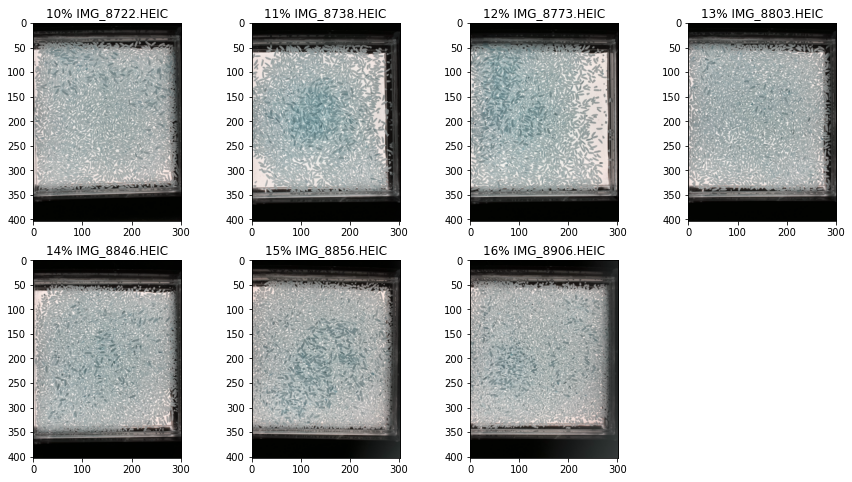

In [42]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [43]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=20
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [44]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,204.916396,355.499342,249.127117,382.159185,7.196217,10.195834,8.093454,10.710400,0.341061,0.270508,...,0.008722,0.008320,0.008395,0.008289,20,806,604,3,IMG_8678.HEIC,10
1,210.663587,344.611878,233.415520,371.101381,7.368783,10.039564,7.822385,10.567331,0.334898,0.269716,...,0.008569,0.008157,0.008241,0.008127,20,806,604,3,IMG_8679.HEIC,10
2,210.930011,361.084606,250.103854,381.909922,7.400286,10.465552,8.302378,10.875987,0.328511,0.257406,...,0.006888,0.006511,0.006597,0.006474,20,806,604,3,IMG_8680.HEIC,10
3,203.965670,349.511206,244.901744,373.665464,7.205863,10.200686,8.172264,10.686062,0.337316,0.266396,...,0.008037,0.007628,0.007728,0.007630,20,806,604,3,IMG_8682.HEIC,10
4,207.868595,346.359202,225.352289,348.300281,7.320517,10.171396,7.754338,10.216044,0.329723,0.262188,...,0.007831,0.007450,0.007561,0.007441,20,806,604,3,IMG_8686.HEIC,10
5,200.325220,359.554754,243.977967,376.876024,7.042976,10.176482,7.966708,10.490382,0.353476,0.279287,...,0.008901,0.008483,0.008585,0.008458,20,806,604,3,IMG_8693.HEIC,10
6,228.272712,405.734168,277.642882,414.817968,7.340619,10.766966,8.498437,10.969941,0.354664,0.276245,...,0.007233,0.006873,0.006974,0.006857,20,806,604,3,IMG_8701.HEIC,10
7,227.735467,401.768730,261.068961,397.410972,7.342506,10.737616,8.164707,10.669042,0.356925,0.277349,...,0.006638,0.006290,0.006400,0.006277,20,806,604,3,IMG_8702.HEIC,10
8,238.080727,421.421448,274.605944,419.225753,7.523645,11.059366,8.406240,11.014907,0.357614,0.276807,...,0.007503,0.007070,0.007215,0.007107,20,806,604,3,IMG_8703.HEIC,10
9,239.156202,414.531086,283.960584,428.900390,7.552294,10.826936,8.539441,11.130153,0.354977,0.280383,...,0.007954,0.007545,0.007677,0.007541,20,806,604,3,IMG_8704.HEIC,10


# Classification

In [45]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [46]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [47]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [48]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [49]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [50]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.809524,0.809524,0.809524,GLCM,C8,RF_C,20,806,604,3
1,2,0.888889,0.942857,0.857143,0.897959,GLCM,C8,RF_C,20,806,604,3
2,3,0.666667,0.726190,0.666667,0.695157,GLCM,C8,RF_C,20,806,604,3
3,4,0.666667,0.607143,0.619048,0.613037,GLCM,C8,RF_C,20,806,604,3
4,5,0.833333,0.871429,0.833333,0.851955,GLCM,C8,RF_C,20,806,604,3
5,6,0.777778,0.821429,0.761905,0.790548,GLCM,C8,RF_C,20,806,604,3
6,7,0.833333,0.869048,0.833333,0.850816,GLCM,C8,RF_C,20,806,604,3
7,8,0.722222,0.809524,0.714286,0.758929,GLCM,C8,RF_C,20,806,604,3
8,9,0.833333,0.892857,0.857143,0.874636,GLCM,C8,RF_C,20,806,604,3
9,10,0.888889,0.880952,0.880952,0.880952,GLCM,C8,RF_C,20,806,604,3


In [51]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C8,RF_C,0.790058,0.783333,0.802351,0.823095


### MLP Classifier

In [52]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [53]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [54]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.797619,0.785714,0.791622,GLCM,C8,MLP_C,20,806,604,3
1,2,0.944444,0.964286,0.928571,0.946092,GLCM,C8,MLP_C,20,806,604,3
2,3,0.722222,0.750000,0.714286,0.731707,GLCM,C8,MLP_C,20,806,604,3
3,4,0.722222,0.752381,0.714286,0.732839,GLCM,C8,MLP_C,20,806,604,3
4,5,0.666667,0.714286,0.666667,0.689655,GLCM,C8,MLP_C,20,806,604,3
5,6,0.833333,0.800000,0.809524,0.804734,GLCM,C8,MLP_C,20,806,604,3
6,7,0.888889,0.880952,0.880952,0.880952,GLCM,C8,MLP_C,20,806,604,3
7,8,0.777778,0.785714,0.785714,0.785714,GLCM,C8,MLP_C,20,806,604,3
8,9,0.722222,0.775510,0.714286,0.743640,GLCM,C8,MLP_C,20,806,604,3
9,10,0.833333,0.880952,0.857143,0.868885,GLCM,C8,MLP_C,20,806,604,3


In [55]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C8,MLP_C,0.790058,0.785714,0.797584,0.81017


### XGBoost Classifier

In [56]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [57]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.894737,0.904762,0.880952,0.892698,GLCM,C8,XGB_C,20,806,604,3
1,2,0.777778,0.797619,0.761905,0.779353,GLCM,C8,XGB_C,20,806,604,3
2,3,0.777778,0.785714,0.785714,0.785714,GLCM,C8,XGB_C,20,806,604,3
3,4,0.888889,0.916667,0.904762,0.910675,GLCM,C8,XGB_C,20,806,604,3
4,5,0.611111,0.657143,0.547619,0.597403,GLCM,C8,XGB_C,20,806,604,3
5,6,0.777778,0.857143,0.785714,0.819876,GLCM,C8,XGB_C,20,806,604,3
6,7,0.833333,0.895238,0.809524,0.850226,GLCM,C8,XGB_C,20,806,604,3
7,8,0.833333,0.880952,0.857143,0.868885,GLCM,C8,XGB_C,20,806,604,3
8,9,0.833333,0.869048,0.857143,0.863054,GLCM,C8,XGB_C,20,806,604,3
9,10,0.777778,0.809524,0.785714,0.797441,GLCM,C8,XGB_C,20,806,604,3


In [58]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C8,XGB_C,0.800585,0.797619,0.816533,0.837381


# External validation

In [59]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C8_10,5,"[DATA/TEST/C8/C8_10/IMG_8685.HEIC, DATA/TEST/C..."
1,C8_11,5,"[DATA/TEST/C8/C8_11/IMG_8732.HEIC, DATA/TEST/C..."
2,C8_12,5,"[DATA/TEST/C8/C8_12/IMG_8762.HEIC, DATA/TEST/C..."
3,C8_13,5,"[DATA/TEST/C8/C8_13/IMG_8792.HEIC, DATA/TEST/C..."
4,C8_14,5,"[DATA/TEST/C8/C8_14/IMG_8827.HEIC, DATA/TEST/C..."
5,C8_15,5,"[DATA/TEST/C8/C8_15/IMG_8854.HEIC, DATA/TEST/C..."
6,C8_16,5,"[DATA/TEST/C8/C8_16/IMG_8901.HEIC, DATA/TEST/C..."


In [60]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [61]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])

        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [62]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,215.356651,375.867351,243.509173,368.272903,7.390197,10.597468,8.091921,10.542952,0.338157,0.265724,...,0.008589,0.008163,0.008249,0.008183,20,806,604,3,IMG_8685.HEIC,10
1,225.187069,368.420383,244.472017,382.774068,7.559747,10.390874,7.999140,10.676823,0.329519,0.264121,...,0.007343,0.006933,0.007080,0.006950,20,806,604,3,IMG_8687.HEIC,10
2,207.550128,349.730713,225.809611,361.938933,7.241390,10.119790,7.715962,10.340354,0.342190,0.273417,...,0.008925,0.008508,0.008613,0.008478,20,806,604,3,IMG_8688.HEIC,10
3,197.468149,351.165699,223.173635,357.215719,6.886611,9.958036,7.515324,10.092939,0.366092,0.292491,...,0.007708,0.007338,0.007443,0.007321,20,806,604,3,IMG_8696.HEIC,10
4,236.079057,389.586879,279.944114,434.195754,7.512535,10.447248,8.534065,11.254358,0.349212,0.280578,...,0.008349,0.007961,0.008059,0.007912,20,806,604,3,IMG_8699.HEIC,10
0,242.826578,434.267408,282.169481,417.497154,7.506051,11.024575,8.429902,10.782829,0.357331,0.281424,...,0.007660,0.007269,0.007427,0.007244,20,806,604,3,IMG_8732.HEIC,11
1,227.546980,402.854183,268.567474,404.714735,7.264883,10.612332,8.188143,10.609369,0.364902,0.288402,...,0.008765,0.008338,0.008522,0.008339,20,806,604,3,IMG_8735.HEIC,11
2,223.066635,390.706635,272.558122,414.815471,7.212330,10.353473,8.249554,10.827993,0.363324,0.292876,...,0.008602,0.008177,0.008359,0.008156,20,806,604,3,IMG_8737.HEIC,11
3,211.341181,363.391335,239.508677,383.490043,7.184705,10.150026,7.909002,10.512294,0.352978,0.283758,...,0.008115,0.007734,0.007936,0.007703,20,806,604,3,IMG_8739.HEIC,11
4,205.017294,331.816887,214.033491,367.491884,6.990554,9.548152,7.335556,10.188187,0.360652,0.295569,...,0.008227,0.007808,0.008041,0.007793,20,806,604,3,IMG_8740.HEIC,11


In [63]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [64]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [65]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [66]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [67]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.60      0.60      0.60         5
     Class 1       0.75      0.60      0.67         5
     Class 2       0.62      1.00      0.77         5
     Class 3       1.00      0.60      0.75         5
     Class 4       0.83      1.00      0.91         5
     Class 5       0.80      0.80      0.80         5
     Class 6       0.75      0.60      0.67         5

    accuracy                           0.74        35
   macro avg       0.77      0.74      0.74        35
weighted avg       0.77      0.74      0.74        35



## MLP

In [68]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [69]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.25      0.40      0.31         5
     Class 1       0.50      0.20      0.29         5
     Class 2       0.71      1.00      0.83         5
     Class 3       0.75      0.60      0.67         5
     Class 4       1.00      0.80      0.89         5
     Class 5       0.83      1.00      0.91         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.69        35
   macro avg       0.72      0.69      0.68        35
weighted avg       0.72      0.69      0.68        35



## XGBC

In [70]:
y_pred = modelXGBC.predict(X_test_scale) 

In [71]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.60      0.55         5
     Class 1       0.67      0.80      0.73         5
     Class 2       0.80      0.80      0.80         5
     Class 3       1.00      0.80      0.89         5
     Class 4       1.00      0.80      0.89         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.80        35
   macro avg       0.83      0.80      0.81        35
weighted avg       0.83      0.80      0.81        35

